In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
#import Libraries
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [3]:
#Run it locally with you Kaggle API token
import kagglehub
kagglehub.login()

from pathlib import Path
path = kagglehub.dataset_download("joniarroba/noshowappointments")
csv_path = Path(path) / "KaggleV2-May-2016.csv"

df = pd.read_csv(csv_path)

In [4]:
df

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110522,2.572134e+12,5651768,F,2016-05-03T09:15:35Z,2016-06-07T00:00:00Z,56,MARIA ORTIZ,0,0,0,0,0,1,No
110523,3.596266e+12,5650093,F,2016-05-03T07:27:33Z,2016-06-07T00:00:00Z,51,MARIA ORTIZ,0,0,0,0,0,1,No
110524,1.557663e+13,5630692,F,2016-04-27T16:03:52Z,2016-06-07T00:00:00Z,21,MARIA ORTIZ,0,0,0,0,0,1,No
110525,9.213493e+13,5630323,F,2016-04-27T15:09:23Z,2016-06-07T00:00:00Z,38,MARIA ORTIZ,0,0,0,0,0,1,No


In [5]:
df.shape

(110527, 14)

In [6]:
dataset_details = pd.DataFrame({
    "column": df.columns,
    "Data Type": [df[col].dtype for col in df.columns],
    "Missing Values": [f"{df[col].isna().mean() * 100:.1f}" for col in df.columns],
    "Unique Values": [df[col].nunique() for col in df.columns],
    "Example Value": [df[col].dropna().iloc[0] if df[col].notna().any() else None for col in df.columns]
})
dataset_details

,column,Data Type,Missing Values,Unique Values,Example Value
0,PatientId,float64,0.0,62299,29872499824296.0
1,AppointmentID,int64,0.0,110527,5642903
2,Gender,str,0.0,2,F
3,ScheduledDay,str,0.0,103549,2016-04-29T18:38:08Z
4,AppointmentDay,str,0.0,27,2016-04-29T00:00:00Z
5,Age,int64,0.0,104,62
6,Neighbourhood,str,0.0,81,JARDIM DA PENHA
7,Scholarship,int64,0.0,2,0
8,Hipertension,int64,0.0,2,1
9,Diabetes,int64,0.0,2,0


In [7]:
#Mapping Features
df_v2 = df.copy()
df_v2.columns = (df.columns
              .str.strip()
              .str.lower()
              .str.replace(r'\s+', '_', regex=True))

df_v2['no-show'] = df_v2['no-show'].map({'Yes': 1, 'No': 0})
df_v2['neighbourhood'] = df_v2['neighbourhood'].str.lower()

In [8]:
df_v2

,patientid,appointmentid,gender,scheduledday,appointmentday,age,neighbourhood,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,jardim da penha,0,1,0,0,0,0,0
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,jardim da penha,0,0,0,0,0,0,0
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,mata da praia,0,0,0,0,0,0,0
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,pontal de camburi,0,0,0,0,0,0,0
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,jardim da penha,0,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110522,2.572134e+12,5651768,F,2016-05-03T09:15:35Z,2016-06-07T00:00:00Z,56,maria ortiz,0,0,0,0,0,1,0
110523,3.596266e+12,5650093,F,2016-05-03T07:27:33Z,2016-06-07T00:00:00Z,51,maria ortiz,0,0,0,0,0,1,0
110524,1.557663e+13,5630692,F,2016-04-27T16:03:52Z,2016-06-07T00:00:00Z,21,maria ortiz,0,0,0,0,0,1,0
110525,9.213493e+13,5630323,F,2016-04-27T15:09:23Z,2016-06-07T00:00:00Z,38,maria ortiz,0,0,0,0,0,1,0


In [9]:
# Days between scheduling and appointment
df_v2['scheduledday'] = pd.to_datetime(df_v2['scheduledday'], utc=True)
df_v2['scheduled_hour'] = df_v2['scheduledday'].dt.hour

df_v2['scheduledday_adjusted'] = df_v2['scheduledday'].dt.normalize()
df_v2['appointmentday'] = pd.to_datetime(df_v2['appointmentday'], utc=True)

df_v2['days_to_appointment'] = (df_v2['appointmentday'] - df_v2['scheduledday_adjusted']).dt.days

In [10]:
# Time-of-day group based on scheduled hour
def hour_to_period(hour):
    if hour < 9:
        return 'early_morning'
    elif hour < 12:
        return 'late_morning'
    elif hour < 15:
        return 'early_afternoon'
    elif hour < 18:
        return 'late_afternoon'
    else:
        return 'evening'

df_v2['period'] = df_v2['scheduled_hour'].apply(hour_to_period)

In [11]:
#Dropping Unnecessary features
df_v2.drop(['appointmentid','scheduledday','appointmentday','scheduledday_adjusted','scheduled_hour'], axis=1, inplace=True)

In [12]:
df_v2

,patientid,gender,age,neighbourhood,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no-show,days_to_appointment,period
0,2.987250e+13,F,62,jardim da penha,0,1,0,0,0,0,0,0,evening
1,5.589978e+14,M,56,jardim da penha,0,0,0,0,0,0,0,0,late_afternoon
2,4.262962e+12,F,62,mata da praia,0,0,0,0,0,0,0,0,late_afternoon
3,8.679512e+11,F,8,pontal de camburi,0,0,0,0,0,0,0,0,late_afternoon
4,8.841186e+12,F,56,jardim da penha,0,1,1,0,0,0,0,0,late_afternoon
...,...,...,...,...,...,...,...,...,...,...,...,...,...
110522,2.572134e+12,F,56,maria ortiz,0,0,0,0,0,1,0,35,late_morning
110523,3.596266e+12,F,51,maria ortiz,0,0,0,0,0,1,0,35,early_morning
110524,1.557663e+13,F,21,maria ortiz,0,0,0,0,0,1,0,41,late_afternoon
110525,9.213493e+13,F,38,maria ortiz,0,0,0,0,0,1,0,41,late_afternoon


In [13]:
# One-hot encoding for features
encoded_df = pd.get_dummies(df_v2, columns=['gender','period'],dtype=int)

#Dropping Unnecessary features
encoded_df.drop('neighbourhood', axis=1, inplace=True)


In [14]:
encoded_df

,patientid,age,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no-show,days_to_appointment,gender_F,gender_M,period_early_afternoon,period_early_morning,period_evening,period_late_afternoon,period_late_morning
0,2.987250e+13,62,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0
1,5.589978e+14,56,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
2,4.262962e+12,62,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
3,8.679512e+11,8,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
4,8.841186e+12,56,0,1,1,0,0,0,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110522,2.572134e+12,56,0,0,0,0,0,1,0,35,1,0,0,0,0,0,1
110523,3.596266e+12,51,0,0,0,0,0,1,0,35,1,0,0,1,0,0,0
110524,1.557663e+13,21,0,0,0,0,0,1,0,41,1,0,0,0,0,1,0
110525,9.213493e+13,38,0,0,0,0,0,1,0,41,1,0,0,0,0,1,0


In [15]:
#Visuals

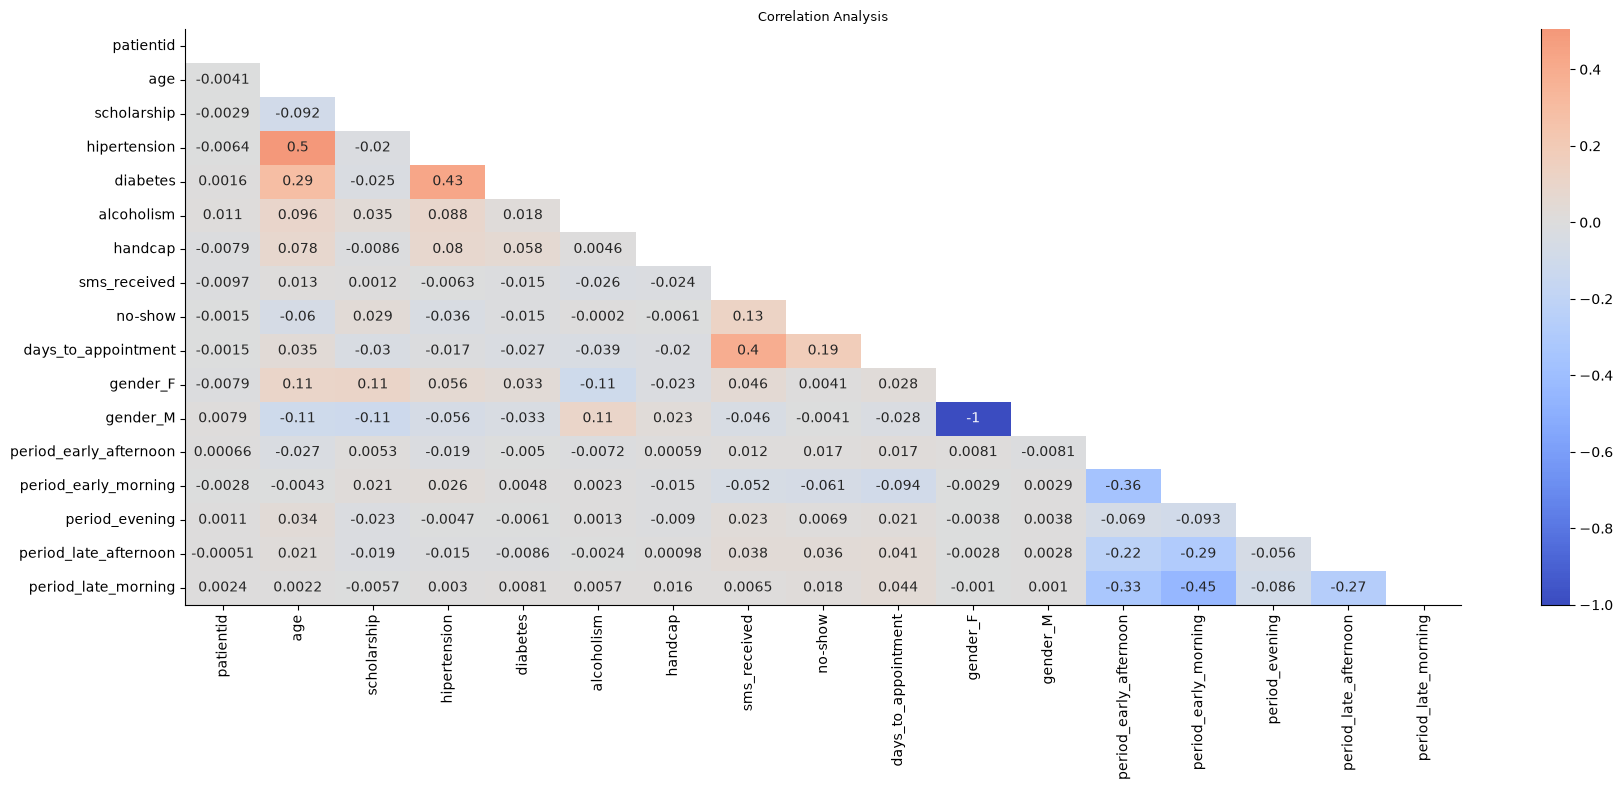

In [19]:
#General correlation of the features

corr = encoded_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool)) # Mask to remove the upper side and facilitate visualization

plt.figure(figsize=(18,8))
sns.heatmap(corr, mask=mask, annot=True, cmap='coolwarm', center=0)

sns.despine(left=False, right=True, top=True, bottom=False)

plt.title("Correlation Analysis", fontsize=9)
plt.tight_layout()

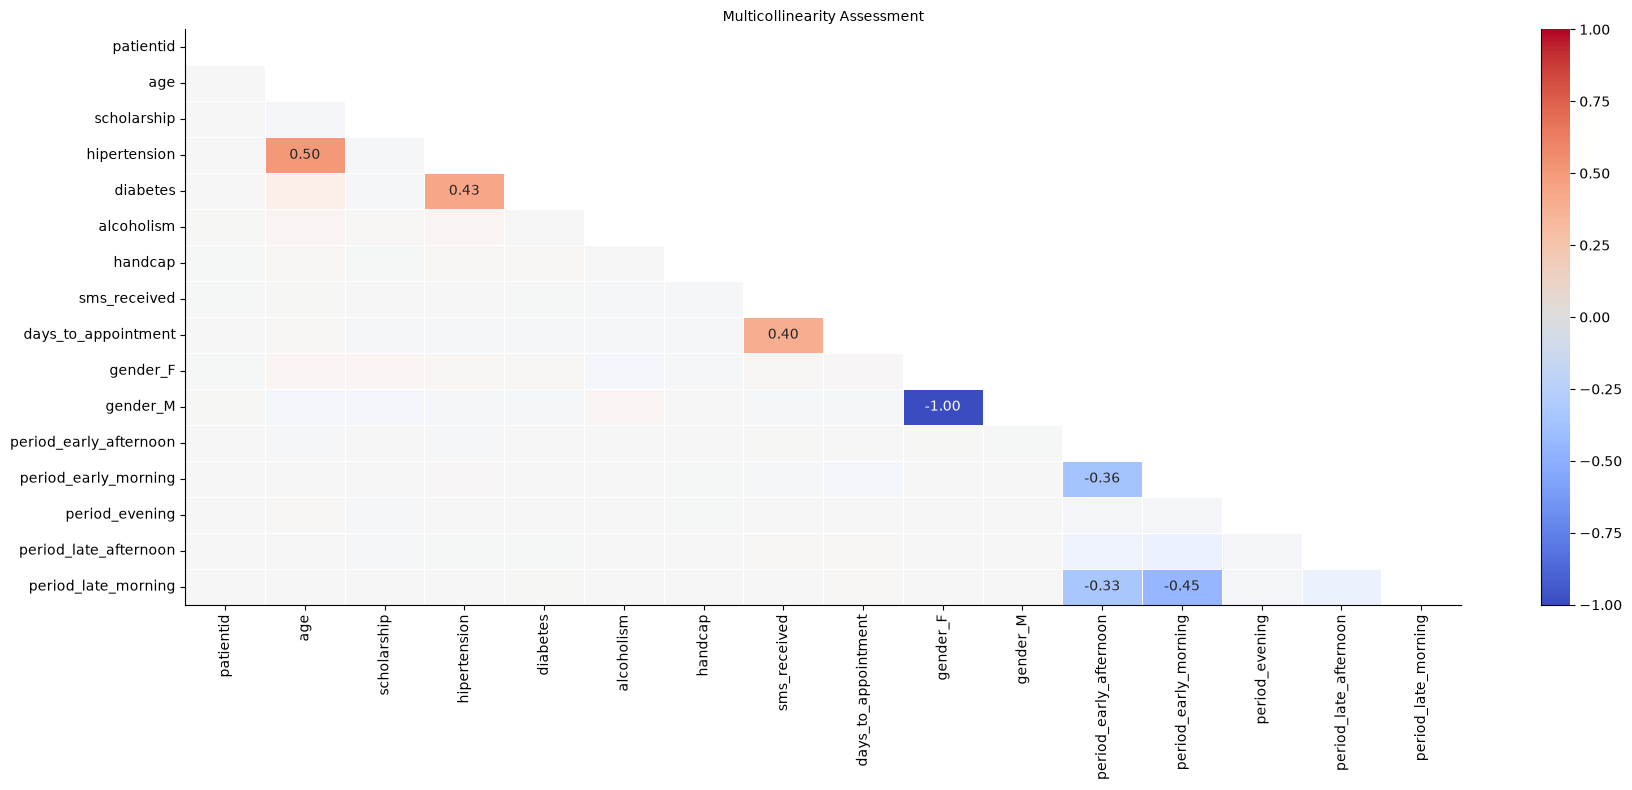

In [16]:
# Multicollinearity Matrix assessment
features = encoded_df.drop(columns=['no-show'])
corr_feat = features.corr()

upper_tri = np.triu(np.ones_like(corr_feat, dtype=bool))
mask = upper_tri | (corr_feat.abs() < 0.3)   # highlight |r| >= 0.5

# Building Visuals
fig, ax = plt.subplots(figsize=(18, 8))

# Faded background showing all pairs
sns.heatmap(corr_feat, mask=np.triu(np.ones_like(corr_feat, dtype=bool)),
            annot=False, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            alpha=0.25, cbar=False, ax=ax)

# Bold overlay for concerning pairs (|r| >= 0.5)
sns.heatmap(corr_feat, mask=mask,
            annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='white', ax=ax)

sns.despine(left=False, right=True, top=True, bottom=False)
ax.set_title("Multicollinearity Assessment", fontsize=10)
plt.tight_layout()

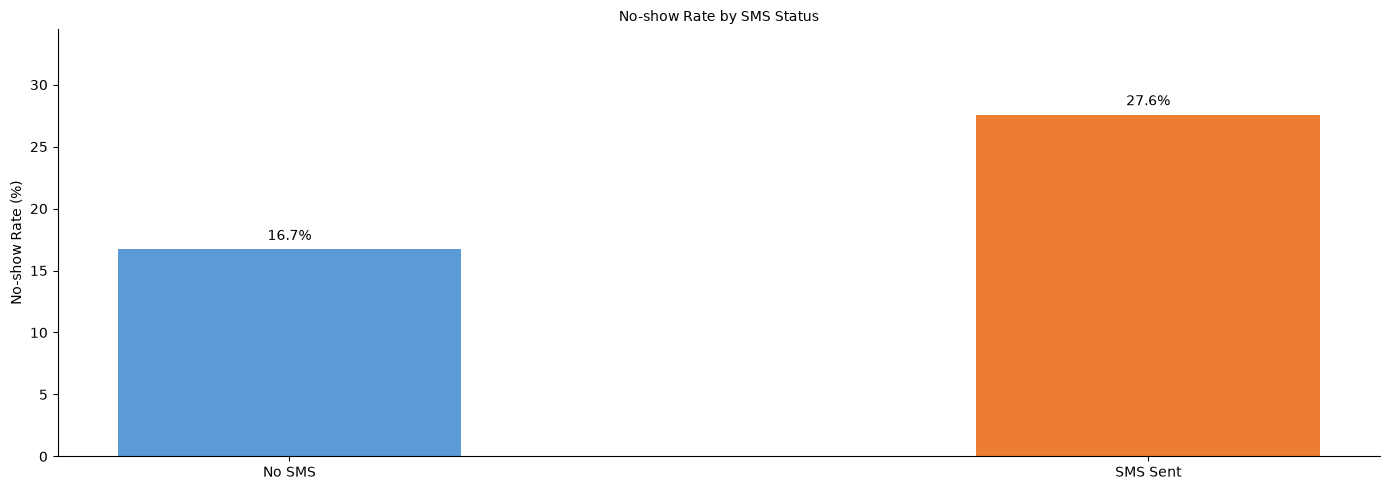

In [42]:
fig, ax = plt.subplots(figsize=(14, 5))

# SMS received vs No-show rate
sms_rate = (df_v2.groupby('sms_received')['no-show'].mean().mul(100).reset_index()
              .rename(columns={'no-show': 'no_show_rate',
                               'sms_received': 'SMS Received'}))

sms_rate['SMS Received'] = sms_rate['SMS Received'].map({0: 'No SMS', 1: 'SMS Sent'})

# Building visuals
bars = ax.bar(sms_rate['SMS Received'], sms_rate['no_show_rate'],
                   color=['#5B9BD5', '#ED7D31'], width=0.4)

for bar, val in zip(bars, sms_rate['no_show_rate']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                 f'{val:.1f}%', ha='center', va='bottom', fontsize=10)

# Adjusting visuals
ax.set_title('No-show Rate by SMS Status', fontsize=10)
ax.set_ylabel('No-show Rate (%)')
ax.set_ylim(0, sms_rate['no_show_rate'].max() * 1.25)
sns.despine(ax=ax)
plt.tight_layout()

In [32]:
sms_rate

,SMS Received,no_show_rate
0,No SMS,16.703311
1,SMS Sent,27.574545


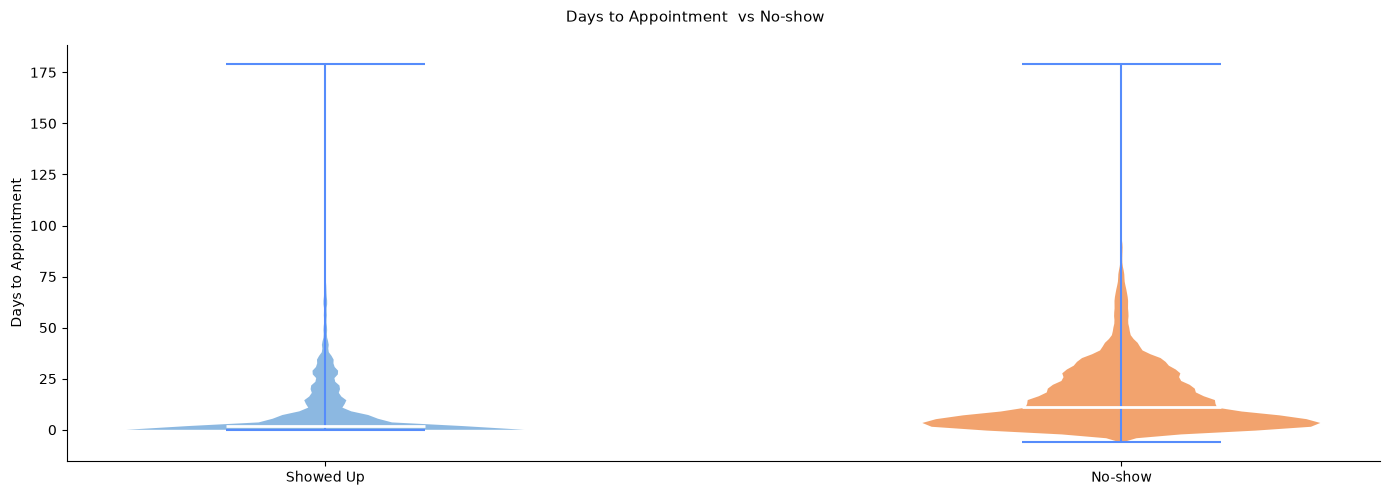

In [51]:
fig, ax = plt.subplots(figsize=(14, 5))

#Days to appointment vs No-show
groups = [df_v2.loc[df_v2['no-show'] == k, 'days_to_appointment'] for k in [0, 1]]
vp = ax.violinplot(groups, positions=[0, 1], showmedians=True)

#Building visuals
colors = ['#5B9BD5', '#ED7D31']
for patch, color in zip(vp['bodies'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
vp['cmedians'].set_color('white')
vp['cmedians'].set_linewidth(2)

#Adjusting visuals
ax.set_xticks([0, 1])
ax.set_xticklabels(['Showed Up', 'No-show'])
ax.set_ylabel('Days to Appointment')

sns.despine(ax=ax)
plt.suptitle('Days to Appointment  vs No-show', fontsize=11)
plt.tight_layout()

In [18]:
# Filtering dataframe to get best features for target variables
corr_target = encoded_df.corr(method='spearman')
target_corr = corr_target['no-show']
corr_matrix_target = target_corr[((target_corr >= 0.1) | (target_corr <= -0.1))]

# Extracting feature names with non-NaN correlation for each target
valuable_features = corr_matrix_target.index.tolist()

# Dataframe to assess diabetes risk score
valuable_features_df = encoded_df[valuable_features]

valuable_features_df


,sms_received,no-show,days_to_appointment
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0
...,...,...,...
110522,1,0,35
110523,1,0,35
110524,1,0,41
110525,1,0,41
